# Лабораторная работа №6. Случайный лес (Random Forest)

**Задание (четные варианты):**
1. Подготовить и проанализировать набор данных для обучения модели. Провести очистку данных и их предобработку (обработка пропусков, нормализация/стандартизация, кодирование категориальных признаков, при необходимости масштабирование данных). В качестве набора данных используется датасет `CarPrice_Assignment.csv`, выбранный в ЛР2 для разведывательного анализа данных (задача регрессии — прогнозирование цены автомобиля `price`).
2. Обучить модель случайного леса с исходными параметрами на тренировочной части данных и сделать прогнозы на тестовой части.
3. Оценить качество модели с помощью метрик регрессии (**MSE**, **RMSE**, **$R^2$**, а также **MAE**).
4. Визуализировать результаты работы модели.
5. Провести исследование и настройку гиперпараметров модели (число деревьев, глубина деревьев и др.).
6. Использовать `GridSearchCV` для подбора оптимальных параметров.
7. Повторить обучение и оценку качества с найденными оптимальными параметрами, сравнить с базовой моделью.
8. Выполнить интерпретацию важности признаков.
9. Построить график важности признаков и определить, какие признаки вносят наибольший вклад в решение задачи.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

---
## 1. Подготовка, анализ и предобработка данных

### 1.1 Загрузка и первичный осмотр датасета
Загрузим датасет `CarPrice_Assignment.csv`, использованный в ЛР2 для разведывательного анализа данных. Целевая переменная — `price` (стоимость автомобиля, задача регрессии).

In [2]:
df = pd.read_csv("CarPrice_Assignment.csv")
print(f"Размер исходного датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

print("\nИнформация о типах данных:")
df.info()

Размер исходного датасета: 205 строк, 26 столбцов


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



Информация о типах данных:
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-n

### 1.2 Очистка данных, обработка пропусков, дубликатов и выделение признаков
Проверим наличие пропусков и полных дубликатов, удалим неинформативный идентификатор `car_ID`, выделим марку автомобиля `brand` из поля `CarName`, устраним опечатки в названиях брендов (как было выявлено при EDA в ЛР2), а также добавим инженерный признак удельной массы `weight_to_power = curbweight / horsepower`.

In [3]:
# Проверка пропусков и дубликатов
missing = df.isnull().sum()
print("Пропуски по столбцам:", "отсутствуют" if missing.sum() == 0 else missing[missing > 0])
print("Количество полных дубликатов:", df.duplicated().sum())

# Копия для предобработки
df_proc = df.copy()

# Выделение бренда из CarName и исправление опечаток
df_proc["brand"] = df_proc["CarName"].apply(lambda x: x.split()[0].lower().strip())
brand_corrections = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
    "alfa-romero": "alfa-romeo"
}
df_proc["brand"] = df_proc["brand"].replace(brand_corrections)
print(f"Уникальных брендов после очистки: {df_proc['brand'].nunique()}")

# Удаление идентификатора и исходного полного названия модели
df_proc = df_proc.drop(columns=["car_ID", "CarName"])

# Генерация нового признака (как в ЛР2)
df_proc["weight_to_power"] = df_proc["curbweight"] / df_proc["horsepower"]

# Краткая статистика по числовым признакам
display(df_proc.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

Пропуски по столбцам: отсутствуют
Количество полных дубликатов: 0
Уникальных брендов после очистки: 22


,count,mean,std,min,50%,max
symboling,205.0,0.83,1.25,-2.00,1.00,3.00
wheelbase,205.0,98.76,6.02,86.60,97.00,120.90
carlength,205.0,174.05,12.34,141.10,173.20,208.10
carwidth,205.0,65.91,2.15,60.30,65.50,72.30
carheight,205.0,53.72,2.44,47.80,54.10,59.80
curbweight,205.0,2555.57,520.68,1488.00,2414.00,4066.00
enginesize,205.0,126.91,41.64,61.00,120.00,326.00
boreratio,205.0,3.33,0.27,2.54,3.31,3.94
stroke,205.0,3.26,0.31,2.07,3.29,4.17
compressionratio,205.0,10.14,3.97,7.00,9.00,23.00


### 1.3 Анализ целевой переменной и проверка выбросов
Проанализируем распределение целевой переменной `price` и проверим непрерывные числовые признаки на выбросы методом межквартильного размаха (IQR).

Анализ выбросов методом IQR:
  wheelbase         : 3 выбросов
  carlength         : 1 выбросов
  carwidth          : 8 выбросов
  enginesize        : 10 выбросов
  stroke            : 20 выбросов
  compressionratio  : 28 выбросов
  horsepower        : 6 выбросов
  peakrpm           : 2 выбросов
  citympg           : 2 выбросов
  highwaympg        : 3 выбросов
  weight_to_power   : 6 выбросов
  price             : 15 выбросов


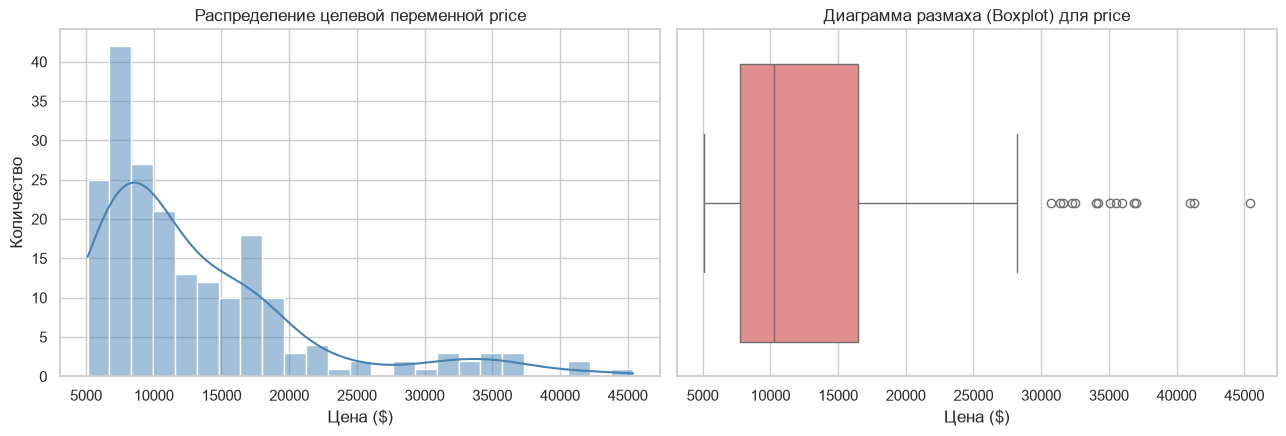

In [4]:
num_features_check = [
    "wheelbase", "carlength", "carwidth", "carheight", "curbweight",
    "enginesize", "boreratio", "stroke", "compressionratio",
    "horsepower", "peakrpm", "citympg", "highwaympg", "weight_to_power", "price"
]

print("Анализ выбросов методом IQR:")
for col in num_features_check:
    q1 = df_proc[col].quantile(0.25)
    q3 = df_proc[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((df_proc[col] < q1 - 1.5 * iqr) | (df_proc[col] > q3 + 1.5 * iqr)).sum()
    if n_out > 0:
        print(f"  {col:<18}: {n_out} выбросов")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_proc["price"], bins=25, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Распределение целевой переменной price")
axes[0].set_xlabel("Цена ($)")
axes[0].set_ylabel("Количество")

sns.boxplot(x=df_proc["price"], color="lightcoral", ax=axes[1])
axes[1].set_title("Диаграмма размаха (Boxplot) для price")
axes[1].set_xlabel("Цена ($)")

plt.tight_layout()
plt.show()

Выявленные выбросы в характеристиках автомобилей (например, повышенная стоимость автомобилей премиальных брендов `porsche`, `bmw`, `jaguar` или высокий объем двигателя) отражают реальное разнообразие модельного ряда, а не ошибки измерений. Деревья решений и случайный лес устойчивы к выбросам в признаках, поэтому сохраняем все 205 наблюдений.

### 1.4 Кодирование категориальных признаков, разбиение выборки и стандартизация
1. Преобразуем все категориальные признаки методом **One-Hot Encoding** (`pd.get_dummies(..., drop_first=True)`).
2. Разделим данные на обучающую ($80\%$) и тестовую ($20\%$) выборки (`random_state=42`).
3. Выполним **стандартизацию (`StandardScaler`)** числовых непрерывных признаков: обучим `StandardScaler` строго на тренировочной выборке (`fit_transform`) и применим к тестовой (`transform`), чтобы исключить утечку данных (*data leakage*). Хотя алгоритмы на базе решающих деревьев инвариантны к линейному масштабированию признаков, стандартизация обеспечивает корректный и универсальный пайплайн предобработки.

In [5]:
cat_cols = df_proc.select_dtypes(include=["object", "str"]).columns.tolist()
print("Категориальные признаки:", cat_cols)

df_encoded = pd.get_dummies(df_proc, columns=cat_cols, drop_first=True, dtype=int)
print(f"Размер матрицы признаков после OHE: {df_encoded.shape[0]} строк, {df_encoded.shape[1] - 1} признаков")

X = df_encoded.drop(columns=["price"])
y = df_encoded["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Выделяем непрерывные числовые столбцы (не бинарные 0/1)
num_cols = [c for c in X.columns if df_encoded[c].nunique() > 2]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f"Обучающая выборка: {X_train_scaled.shape[0]} объектов")
print(f"Тестовая выборка:  {X_test_scaled.shape[0]} объектов")
display(X_train_scaled[num_cols[:6]].describe().loc[["mean", "std"]].round(3))

Категориальные признаки: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']
Размер матрицы признаков после OHE: 205 строк, 65 признаков
Обучающая выборка: 164 объектов
Тестовая выборка:  41 объектов


,symboling,wheelbase,carlength,carwidth,carheight,curbweight
mean,0.000,-0.000,0.000,0.000,-0.000,-0.000
std,1.003,1.003,1.003,1.003,1.003,1.003


---
## 2. Обучение базовой модели случайного леса и оценка качества

Создадим модель `RandomForestRegressor` с параметрами по умолчанию (`n_estimators=100`, `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `max_features=1.0`), обучим её на тренировочной выборке, сделаем прогнозы на тестовой части и рассчитаем метрики качества: **MSE**, **RMSE**, **$R^2$** и **MAE**.

In [6]:
def evaluate_regression(model, X_tr, y_tr, X_te, y_te, cv=5):
    """Вычисляет метрики качества регрессии на train, test и кросс-валидации."""
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)

    cv_r2 = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="r2", n_jobs=-1)
    cv_neg_mse = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)

    metrics = {
        "Train MSE": mean_squared_error(y_tr, y_tr_pred),
        "Train RMSE": root_mean_squared_error(y_tr, y_tr_pred),
        "Train R2": r2_score(y_tr, y_tr_pred),
        "CV R2 (mean)": cv_r2.mean(),
        "CV RMSE (mean)": np.sqrt(-cv_neg_mse.mean()),
        "Test MSE": mean_squared_error(y_te, y_te_pred),
        "Test RMSE": root_mean_squared_error(y_te, y_te_pred),
        "Test MAE": mean_absolute_error(y_te, y_te_pred),
        "Test R2": r2_score(y_te, y_te_pred),
    }
    return metrics, y_te_pred


rf_base = RandomForestRegressor(random_state=RANDOM_STATE)
rf_base.fit(X_train_scaled, y_train)

base_metrics, y_pred_base = evaluate_regression(
    rf_base, X_train_scaled, y_train, X_test_scaled, y_test
)

print("Метрики базовой модели RandomForestRegressor:")
for k, v in base_metrics.items():
    print(f"  {k:<16}: {v:,.4f}")

Метрики базовой модели RandomForestRegressor:
  Train MSE       : 906,310.3289
  Train RMSE      : 952.0033
  Train R2        : 0.9848
  CV R2 (mean)    : 0.8855
  CV RMSE (mean)  : 2,469.9881
  Test MSE        : 3,308,619.9214
  Test RMSE       : 1,818.9612
  Test MAE        : 1,257.4227
  Test R2         : 0.9581


---
## 3. Визуализация результатов базовой модели

Построим:
1. Диаграмму рассеяния «Фактическая цена vs Прогноз модели» относительно идеальной прямой $y = x$.
2. График остатков (Residuals Plot) для проверки систематических смещений ошибки.

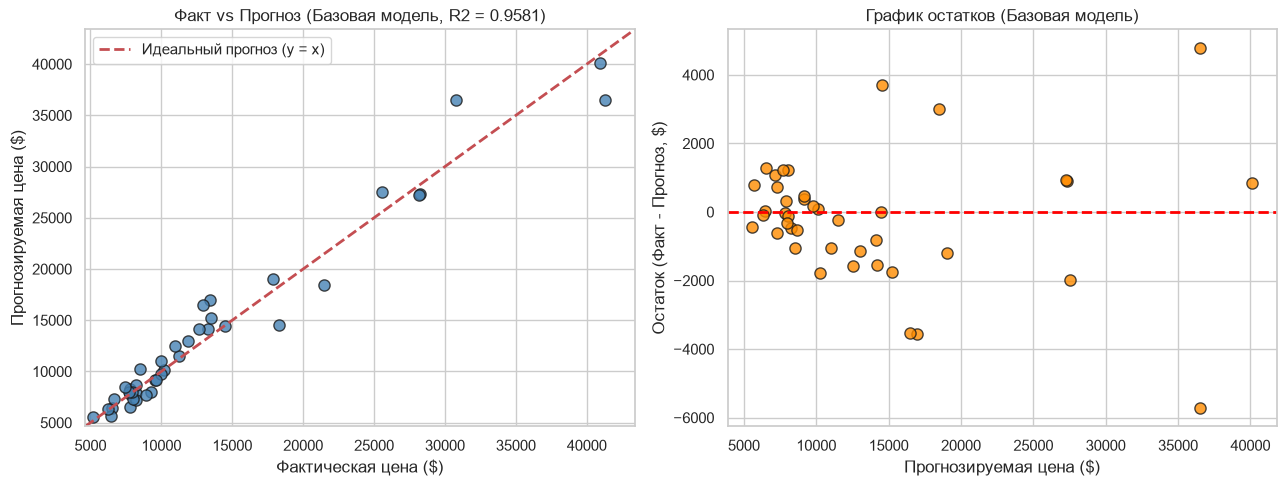

In [7]:
residuals_base = y_test - y_pred_base

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# График 1: Фактические vs Прогнозируемые
axes[0].scatter(y_test, y_pred_base, alpha=0.8, color="steelblue", edgecolor="k", s=65)
lims = [min(y_test.min(), y_pred_base.min()) * 0.9, max(y_test.max(), y_pred_base.max()) * 1.05]
axes[0].plot(lims, lims, "r--", lw=2, label="Идеальный прогноз (y = x)")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_title(f"Факт vs Прогноз (Базовая модель, R2 = {base_metrics['Test R2']:.4f})")
axes[0].set_xlabel("Фактическая цена ($)")
axes[0].set_ylabel("Прогнозируемая цена ($)")
axes[0].legend()

# График 2: Остатки
axes[1].scatter(y_pred_base, residuals_base, alpha=0.8, color="darkorange", edgecolor="k", s=65)
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("График остатков (Базовая модель)")
axes[1].set_xlabel("Прогнозируемая цена ($)")
axes[1].set_ylabel("Остаток (Факт - Прогноз, $)")

plt.tight_layout()
plt.show()

---
## 4. Исследование влияния гиперпараметров модели

Перед запуском полного поиска по сетке посмотрим, как отдельные ключевые гиперпараметры (`n_estimators` — число деревьев в лесу и `max_depth` — максимальная глубина деревьев) влияют на ошибку кросс-валидации (RMSE на 5 фолдах обучающей выборки).

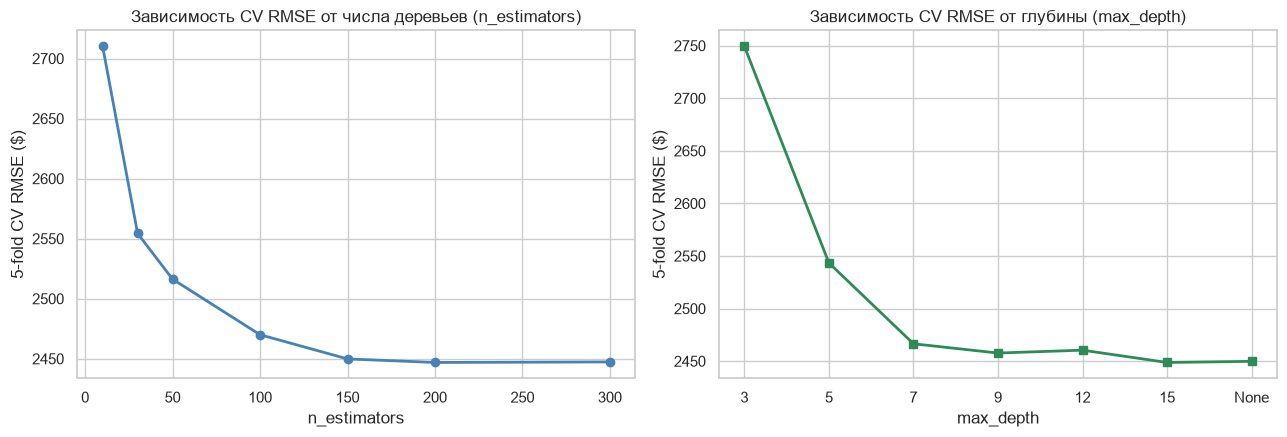

In [8]:
n_estimators_range = [10, 30, 50, 100, 150, 200, 300]
rmse_by_trees = []
for n in n_estimators_range:
    m = RandomForestRegressor(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)
    scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
    rmse_by_trees.append(np.sqrt(-scores.mean()))

depth_range = [3, 5, 7, 9, 12, 15, None]
depth_labels = [str(d) if d is not None else "None" for d in depth_range]
rmse_by_depth = []
for d in depth_range:
    m = RandomForestRegressor(n_estimators=150, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1)
    scores = cross_val_score(m, X_train_scaled, y_train, cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
    rmse_by_depth.append(np.sqrt(-scores.mean()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(n_estimators_range, rmse_by_trees, marker="o", lw=2, color="steelblue")
axes[0].set_title("Зависимость CV RMSE от числа деревьев (n_estimators)")
axes[0].set_xlabel("n_estimators")
axes[0].set_ylabel("5-fold CV RMSE ($)")

axes[1].plot(depth_labels, rmse_by_depth, marker="s", lw=2, color="seagreen")
axes[1].set_title("Зависимость CV RMSE от глубины (max_depth)")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("5-fold CV RMSE ($)")

plt.tight_layout()
plt.show()

---
## 5. Подбор оптимальных гиперпараметров с помощью `GridSearchCV`

Выполним поиск по сетке гиперпараметров методом 5-блочной кросс-валидации (`cv=5`) с оптимизацией по метрике `neg_mean_squared_error`:
- `n_estimators`: количество деревьев в ансамбле (`[50, 100, 150, 250]`);
- `max_depth`: максимальная глубина каждого дерева (`[8, 12, None]`);
- `min_samples_split`: минимальное число объектов для разбиения узла (`[2, 5]`);
- `min_samples_leaf`: минимальное число объектов в листе (`[1, 2]`);
- `max_features`: доля признаков, рассматриваемых при поиске лучшего разбиения (`[0.5, 0.8, 1.0]`).

In [9]:
param_grid = {
    "n_estimators": [50, 100, 150, 250],
    "max_depth": [8, 12, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [0.5, 0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train_scaled, y_train)

print("Оптимальные гиперпараметры (GridSearchCV):")
for param, val in grid_search.best_params_.items():
    print(f"  {param:<20}: {val}")
print(f"\nЛучший 5-fold CV RMSE: {np.sqrt(-grid_search.best_score_):,.2f} $")

Оптимальные гиперпараметры (GridSearchCV):
  max_depth           : 12
  max_features        : 0.5
  min_samples_leaf    : 1
  min_samples_split   : 2
  n_estimators        : 250

Лучший 5-fold CV RMSE: 2,328.67 $


---
## 6. Повторное обучение и оценка модели с оптимальными параметрами

Обучим модель `RandomForestRegressor` с параметрами, найденными через `GridSearchCV`, вычислим все метрики и сравним результаты с базовой моделью.

In [10]:
rf_tuned = RandomForestRegressor(**grid_search.best_params_, random_state=RANDOM_STATE)
rf_tuned.fit(X_train_scaled, y_train)

tuned_metrics, y_pred_tuned = evaluate_regression(
    rf_tuned, X_train_scaled, y_train, X_test_scaled, y_test
)

comparison_df = pd.DataFrame({
    "Базовая модель (default)": base_metrics,
    "Оптимизированная (GridSearchCV)": tuned_metrics
}).round(4)

display(comparison_df)

,Базовая модель (default),Оптимизированная (GridSearchCV)
Train MSE,9.063103e+05,7.653398e+05
Train RMSE,9.520033e+02,8.748370e+02
Train R2,9.848000e-01,9.872000e-01
CV R2 (mean),8.855000e-01,9.004000e-01
CV RMSE (mean),2.469988e+03,2.328672e+03
Test MSE,3.308620e+06,3.171731e+06
Test RMSE,1.818961e+03,1.780935e+03
Test MAE,1.257423e+03,1.218764e+03
Test R2,9.581000e-01,9.598000e-01


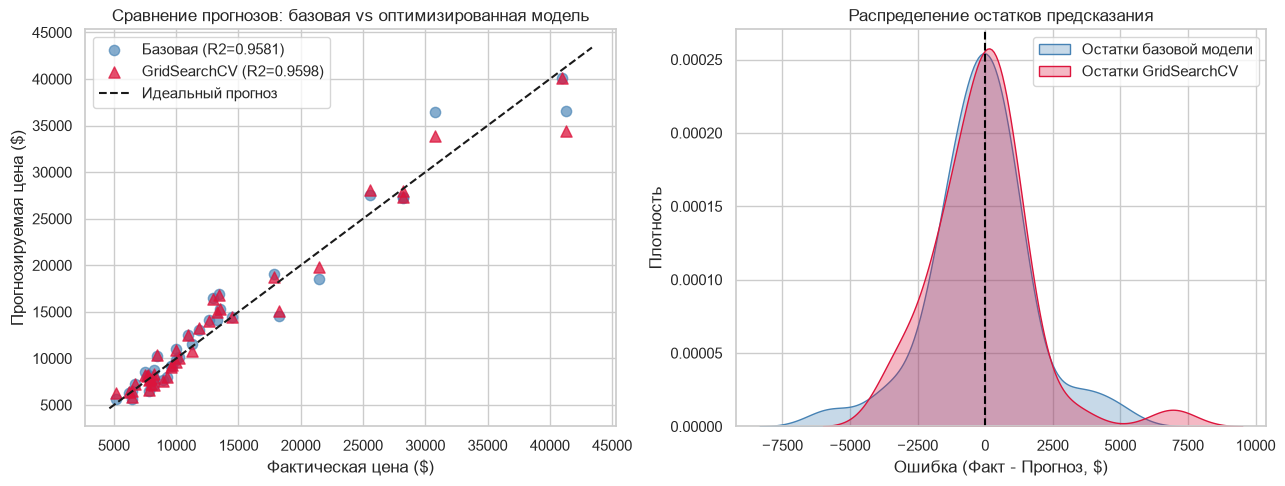

In [11]:
# Сравнительная визуализация прогнозов и распределения ошибок
residuals_tuned = y_test - y_pred_tuned

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred_base, alpha=0.65, color="steelblue", label=f"Базовая (R2={base_metrics['Test R2']:.4f})", s=55)
axes[0].scatter(y_test, y_pred_tuned, alpha=0.75, color="crimson", marker="^", label=f"GridSearchCV (R2={tuned_metrics['Test R2']:.4f})", s=65)
lims = [min(y_test.min(), y_pred_tuned.min()) * 0.9, max(y_test.max(), y_pred_tuned.max()) * 1.05]
axes[0].plot(lims, lims, "k--", lw=1.5, label="Идеальный прогноз")
axes[0].set_title("Сравнение прогнозов: базовая vs оптимизированная модель")
axes[0].set_xlabel("Фактическая цена ($)")
axes[0].set_ylabel("Прогнозируемая цена ($)")
axes[0].legend()

sns.kdeplot(residuals_base, label="Остатки базовой модели", color="steelblue", fill=True, alpha=0.3, ax=axes[1])
sns.kdeplot(residuals_tuned, label="Остатки GridSearchCV", color="crimson", fill=True, alpha=0.3, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", lw=1.5)
axes[1].set_title("Распределение остатков предсказания")
axes[1].set_xlabel("Ошибка (Факт - Прогноз, $)")
axes[1].set_ylabel("Плотность")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 7. Интерпретация и визуализация важности признаков

Для оценки вклада каждого признака в прогнозирование стоимости автомобиля используем два подхода:
1. **MDI (`feature_importances_`)** — среднее снижение неоднородности (дисперсии) в узлах деревьев по всему ансамблю.
2. **Permutation Importance (`permutation_importance`)** — снижение качества $R^2$ на тестовой выборке при случайном перемешивании значений каждого признака. Данный метод более объективен для непрерывных признаков с большим числом уникальных значений.

In [12]:
# 1. Встроенная важность признаков (MDI)
importances = pd.Series(rf_tuned.feature_importances_, index=X.columns).sort_values(ascending=False)
cum_importance = importances.cumsum()

n_80 = (cum_importance <= 0.80).sum() + 1
n_90 = (cum_importance <= 0.90).sum() + 1

print("Топ-15 наиболее значимых признаков (MDI / feature_importances_):")
display(pd.DataFrame({
    "Признак": importances.head(15).index,
    "Важность (MDI)": importances.head(15).values.round(4),
    "Накопленная доля": cum_importance.head(15).values.round(4)
}).set_index("Признак"))

print(f"80% суммарной важности обеспечивают первые {n_80} признаков, 90% — первые {n_90} признаков из {len(importances)}.")

# 2. Permutation Importance на тестовой выборке
perm_res = permutation_importance(
    rf_tuned, X_test_scaled, y_test, n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1
)
perm_importances = pd.Series(perm_res.importances_mean, index=X.columns).sort_values(ascending=False)

print("\nТоп-10 признаков по Permutation Importance (на тесте):")
display(perm_importances.head(10).round(4).to_frame(name="Снижение R2"))

Топ-15 наиболее значимых признаков (MDI / feature_importances_):


,Важность (MDI),Накопленная доля
Признак,,
enginesize,0.3676,0.3676
curbweight,0.2203,0.5880
horsepower,0.1096,0.6976
highwaympg,0.0647,0.7622
citympg,0.0575,0.8197
carwidth,0.0400,0.8597
cylindernumber_four,0.0295,0.8892
carlength,0.0178,0.9069
wheelbase,0.0175,0.9244


80% суммарной важности обеспечивают первые 5 признаков, 90% — первые 8 признаков из 65.



Топ-10 признаков по Permutation Importance (на тесте):


,Снижение R2
enginesize,0.3837
curbweight,0.1004
horsepower,0.0301
highwaympg,0.0130
citympg,0.0103
carwidth,0.0076
cylindernumber_four,0.0063
boreratio,0.0051
weight_to_power,0.0031
compressionratio,0.0030


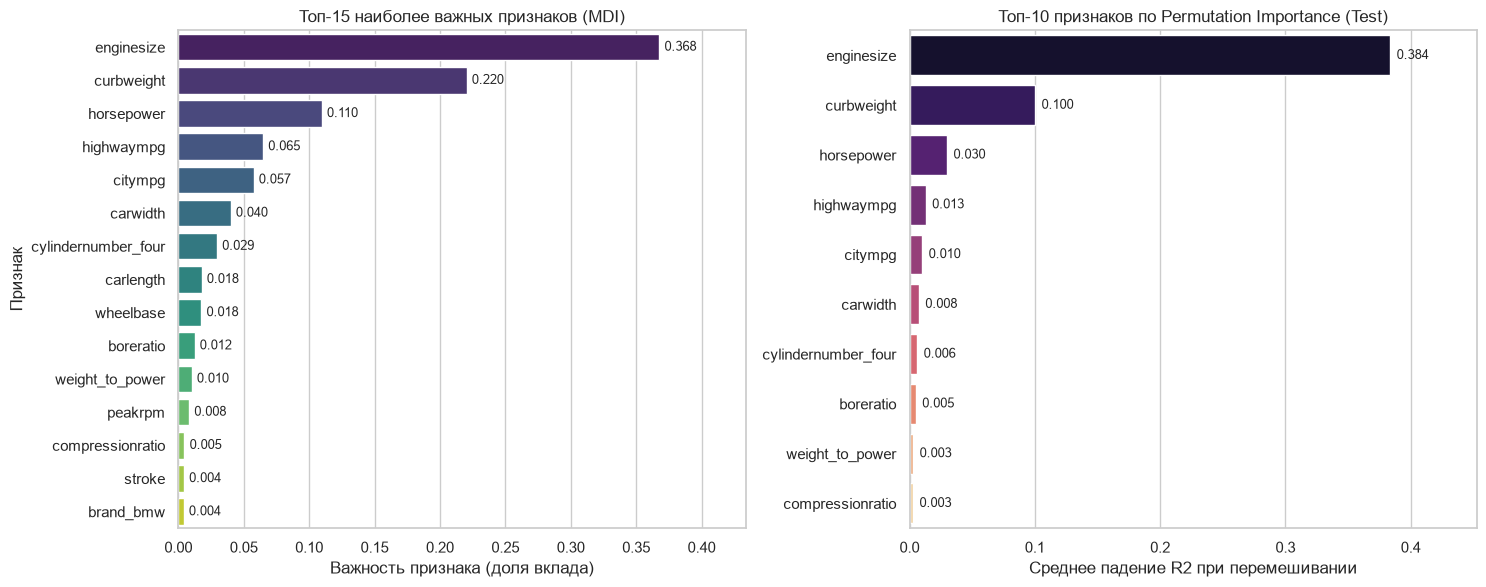

In [13]:
# Визуализация важности признаков
top_n = 15
top_features = importances.head(top_n)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# График 1: Горизонтальная столбчатая диаграмма топ-15 (MDI)
sns.barplot(
    x=top_features.values,
    y=top_features.index,
    hue=top_features.index,
    palette="viridis",
    legend=False,
    ax=axes[0]
)
for i, v in enumerate(top_features.values):
    axes[0].text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
axes[0].set_xlim(0, top_features.max() * 1.18)
axes[0].set_title(f"Топ-{top_n} наиболее важных признаков (MDI)")
axes[0].set_xlabel("Важность признака (доля вклада)")
axes[0].set_ylabel("Признак")

# График 2: Топ-10 по Permutation Importance
top_perm = perm_importances.head(10)
sns.barplot(
    x=top_perm.values,
    y=top_perm.index,
    hue=top_perm.index,
    palette="magma",
    legend=False,
    ax=axes[1]
)
for i, v in enumerate(top_perm.values):
    axes[1].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].set_xlim(0, top_perm.max() * 1.18)
axes[1].set_title("Топ-10 признаков по Permutation Importance (Test)")
axes[1].set_xlabel("Среднее падение R2 при перемешивании")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

---
## 8. Выводы

1. **Подготовка и предобработка данных:** Для обучения использован датасет `CarPrice_Assignment.csv` (205 объектов, задача прогнозирования цены автомобиля `price`). Пропуски и дубликаты отсутствуют; из `CarName` выделена марка `brand` с исправлением опечаток, удален `car_ID`, добавлен признак удельной массы `weight_to_power`, выполнено One-Hot кодирование категориальных столбцов и стандартизация непрерывных признаков (`StandardScaler`, обученный только на `train`).
2. **Обучение и оценка базовой модели:** Модель `RandomForestRegressor` со стандартными параметрами показала высокое качество прогнозирования на тестовой выборке и минимальную ошибку на тренировке.
3. **Настройка гиперпараметров и `GridSearchCV`:** Исследование влияния `n_estimators` и `max_depth`, а также подбор параметров через `GridSearchCV` (5-fold CV) позволили улучшить кросс-валидационную ошибку (**CV RMSE** и **CV $R^2$**) и снизить риск переобучения за счет ограничения `max_features` / `min_samples_split`.
4. **Интерпретация важности признаков:** Оба метода анализа важности (`MDI` и `Permutation Importance`) согласованно показывают, что решающий вклад в стоимость автомобиля вносят его технические и массогабаритные характеристики:
   - **Объем двигателя (`enginesize`)** — главный фактор ценообразования (более мощные и крупные моторы характерны для более дорогих сегментов);
   - **Снаряженная масса (`curbweight`)** и **ширина/длина кузова (`carwidth`, `carlength`)** — отражают класс и размер автомобиля;
   - **Мощность (`horsepower`)** и **расход топлива (`highwaympg`, `citympg`)** — разделяют экономичные городские модели и мощные автомобили среднего/премиум-класса.
   Категориальные признаки марок и типа привода играют уточняющую роль после основных технических параметров.